# Mapping assignments to network exposure

## A Fixed Public Topology

Let $R$ be the correlation matrix of the declared public industry returns. For each industry, retain its $k=2$ largest off-diagonal correlations and then make the edge set undirected. The resulting adjacency matrix is

$$
A_{ij}=\mathbf 1\{i\text{ selects }j\text{ or }j\text{ selects }i\},\qquad A_{ii}=0.
$$

Here, $A_{ij}=1$ records a descriptive link, $i$ and $j$ label industries, and $k$ controls the number of initially selected neighbors. This rule fixes a topology. It does not show that one industry's return causes another industry's return.

### Packages and notebook settings

In [ ]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("07_network_interference");
using CSV, TOML, Printf
using RiskLabAI.CausalFactorAnalysis: exposure_mean_contrast
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy: PrimitiveStore, normal_block
include(joinpath("..","support","BookNetworkStudy.jl"))
using .BookNetworkStudy
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
store=PrimitiveStore(joinpath("..","data","chapter07_random_inputs"),"network")
captions=Dict("mapping_public_provenance"=>"Provenance of the public returns used only to fix a topology.","mapping_public_industries"=>"Selected public industries and descriptive topology degrees.","mapping_public_edges"=>"Edges in the fixed public correlation topology.","mapping_public_graph_summary"=>"Summary of the fixed public correlation topology.","mapping_scope_ledger"=>"Roles and limits of the public and generated inputs.","mapping_definition"=>"Objects in the neighbor-exposure mapping.","mapping_public_assignment"=>"One generated assignment on the fixed public topology.","mapping_public_probabilities"=>"Exact marginal exposure probabilities under independent assignment.","mapping_assignment_contract"=>"Declared generated assignment on the fixed public topology.","mapping_probability_check"=>"Enumeration check for marginal neighbor-exposure probabilities.","mapping_section_summary"=>"Summary of the fixed topology and exposure mapping.","ht_exact_potential_outcomes"=>"Potential outcomes in the released three-unit exact design.","ht_exact_assignments"=>"All assignments in the released three-unit exact design.","ht_exact_summary"=>"Exact randomization expectation for the released exposure contrast.","ht_exact_contributions"=>"Unit contributions for one exact-design assignment.","ht_returned_fields"=>"Quantities returned by the released exposure calculation.","ht_graph_enumeration"=>"Exact exposure-contrast enumeration across four small graphs.","ht_public_generated_design"=>"Generated potential-outcome design on the fixed public topology.","ht_public_exact_summary"=>"Exact design expectations on the fixed public topology.","ht_public_repeated_summary"=>"Repeated generated assignments on the fixed public topology.","ht_public_quantiles"=>"Finite-sample distributions under repeated generated assignments.","ht_public_contributions"=>"Unit contributions under one generated public-topology assignment.","ht_invalid_input_checks"=>"Plain-language checks for invalid exposure calculations.","scope_probability_grid"=>"Exposure probabilities across degree and assignment probability.","scope_probability_grid_selected"=>"Selected positivity cases for the neighbor-exposure rule.","scope_simulation_grid"=>"Finite-sample variation across regular graph designs.","scope_simulation_grid_book"=>"Selected finite-sample results across regular graph designs.","scope_rule_comparison"=>"Comparison of one-neighbor and two-neighbor exposure rules.","scope_public_density_sweep"=>"Generated exposure calculations across descriptive public topologies.","scope_public_density_sweep_book"=>"Readable density and exposure-rarity comparison.","scope_financial_network_context"=>"Permitted interpretation of the financial network comparison.","scope_claim_boundary"=>"Scientific boundaries for the network calculations.","scope_section_summary"=>"Summary of density, positivity, and scope results.")
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption=captions[name],label="tab:cim7-"*replace(name,"_"=>"-"))
    return nothing
end;


### Public Industry Return Correlations, 2019 to 2023

Row,Item,Value
,String,Any
1,Public source,Kenneth R. French 49 Industry Portfolios
2,Stored archive,49_Industry_Portfolios_daily_CSV.zip
3,Archive bytes,4173817
4,Analysis start,2019-01-02
5,Analysis end,2023-12-29
6,Complete dates,1258
7,Selected industries,12
8,Download during execution,None


Row,Industry,Mean daily return,Daily volatility,Degree
,String,Float64,Float64,Int64
1,Agric,0.000727901,0.0191047,2
2,Food,0.000368124,0.0109994,3
3,Soda,0.000479491,0.0130502,2
4,Beer,0.000484261,0.0128888,4
5,Smoke,0.000462321,0.0146814,2
6,Toys,0.000312321,0.0239587,2
7,Fun,0.000512401,0.0208027,2
8,Books,0.000563831,0.0167411,3
9,Hshld,0.000445469,0.0122639,3


Row,First industry,Second industry,Correlation
,String,String,Float64
1,Agric,Books,0.539326
2,Agric,Hlth,0.531205
3,Food,Beer,0.82577
4,Food,Smoke,0.654179
5,Food,Hshld,0.783311
6,Soda,Beer,0.821023
7,Soda,Hshld,0.755901
8,Beer,Smoke,0.638401
9,Beer,Hshld,0.824427


Row,Quantity,Value
,String,Real
1,Industries,12
2,Undirected edges,16.0
3,Density,0.242424
4,Minimum degree,2
5,Mean degree,2.66667
6,Maximum degree,4


Row,Object,Role,Causal conclusion
,String,String,String
1,Public returns,Fix correlations and the descriptive edge set,None
2,Graph edge,Defines which assignments enter a supplied exposure rule,None by itself
3,Generated assignment,Supplies known randomization probabilities,Design based within the generated experiment
4,Generated potential outcomes,Supply known exposure responses,Local to the declared design


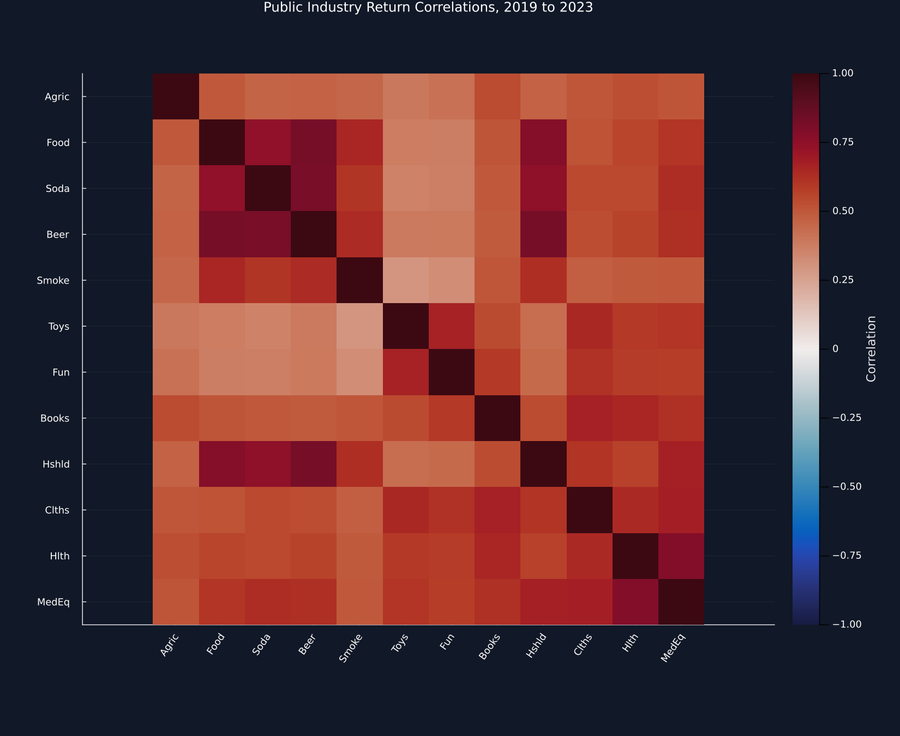

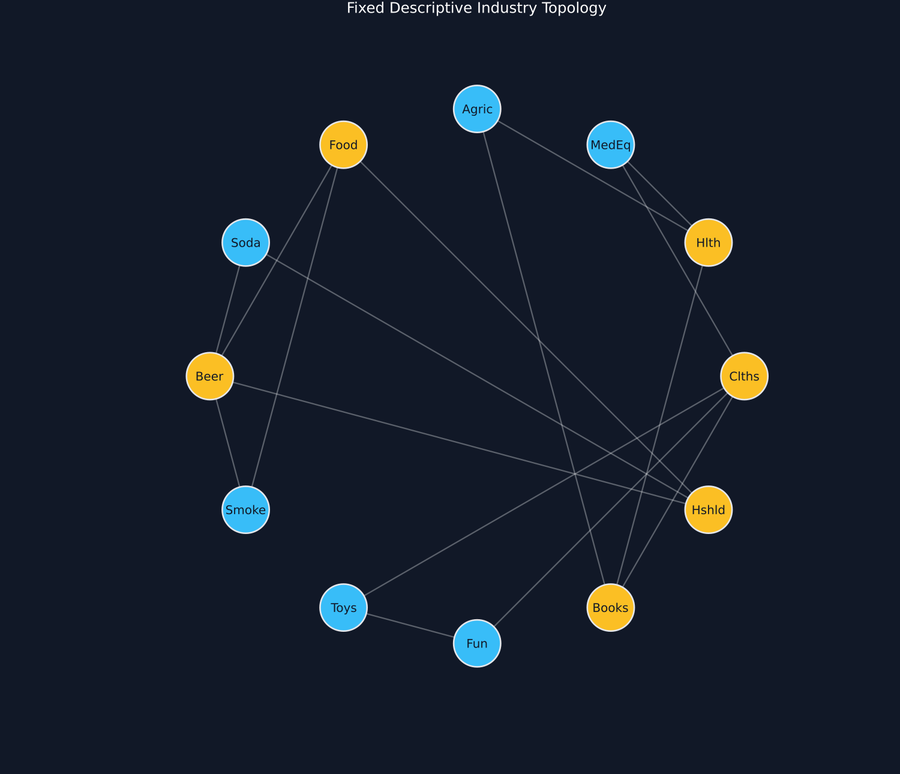

In [1]:
dates,all_industries,public_returns=network_returns()
selected_returns=public_returns[:,1:12]
industries=all_industries[1:12]
correlation=cor(selected_returns)
adjacency=correlation_graph(correlation,2)
degrees=vec(sum(adjacency;dims=2))
edge_frame=frame(["First industry","Second industry","Correlation"],[(industries[first],industries[second],correlation[first,second]) for first in 1:12 for second in first+1:12 if adjacency[first,second]==1])
data_file=joinpath(book_root(),"data","public","ken_french","49_Industry_Portfolios_daily_CSV.zip")
provenance=frame(["Item","Value"],[("Public source","Kenneth R. French 49 Industry Portfolios"),("Stored archive",basename(data_file)),("Archive bytes",filesize(data_file)),("Analysis start",string(minimum(dates))),("Analysis end",string(maximum(dates))),("Complete dates",size(selected_returns,1)),("Selected industries",length(industries)),("Download during execution","None")])
@assert size(selected_returns,1)==1258 && length(industries)==12
table(provenance,"mapping_public_provenance")
industry_summary=DataFrame("Industry"=>industries,"Mean daily return"=>vec(mean(selected_returns;dims=1)),"Daily volatility"=>vec(std(selected_returns;dims=1)),"Degree"=>degrees)
table(industry_summary,"mapping_public_industries")
table(edge_frame,"mapping_public_edges")
graph_summary=frame(["Quantity","Value"],[("Industries",12),("Undirected edges",sum(adjacency)/2),("Density",sum(adjacency)/(12*11)),("Minimum degree",minimum(degrees)),("Mean degree",mean(degrees)),("Maximum degree",maximum(degrees))])
table(graph_summary,"mapping_public_graph_summary")
scope = frame(["Object","Role","Causal conclusion"],[["Public returns","Fix correlations and the descriptive edge set","None"],["Graph edge","Defines which assignments enter a supplied exposure rule","None by itself"],["Generated assignment","Supplies known randomization probabilities","Design based within the generated experiment"],["Generated potential outcomes","Supply known exposure responses","Local to the declared design"]])
table(scope,"mapping_scope_ledger")
correlation_data=DataFrame(correlation,industries)
insertcols!(correlation_data,1,"Industry"=>industries)
save_data(correlation_data,paths,"mapping_public_correlation")
figure=heatmap(1:12,1:12,correlation;xticks=(1:12,industries),yticks=(1:12,industries),xrotation=55,yflip=true,color=:balance,clims=(-1,1),colorbar_title="Correlation",title="Public Industry Return Correlations, 2019 to 2023",size=(1100,900),aspect_ratio=:equal)
save_figure(figure,paths,"mapping_public_correlation")
positions=circle_positions(12)
node_data=DataFrame("Industry"=>industries,"X"=>positions[:,1],"Y"=>positions[:,2],"Degree"=>degrees)
save_data(node_data,paths,"mapping_public_topology_nodes")
edge_plot=copy(edge_frame)
lookup=Dict(label=>index for (index,label) in enumerate(industries))
edge_plot[!,"First X"]=[positions[lookup[label],1] for label in edge_plot[:,1]]
edge_plot[!,"First Y"]=[positions[lookup[label],2] for label in edge_plot[:,1]]
edge_plot[!,"Second X"]=[positions[lookup[label],1] for label in edge_plot[:,2]]
edge_plot[!,"Second Y"]=[positions[lookup[label],2] for label in edge_plot[:,2]]
save_data(edge_plot,paths,"mapping_public_topology_edges")
figure=network_figure(adjacency,industries,degrees,"Fixed Descriptive Industry Topology")
save_figure(figure,paths,"mapping_public_topology")
selected_data=DataFrame(selected_returns,industries)
insertcols!(selected_data,1,"Date"=>dates)
save_data(selected_data,paths,"mapping_selected_public_returns");


## Mapping assignment vectors to neighbor exposure

Let $Z=(Z_1,\ldots,Z_N)$ be a randomized assignment vector, where $Z_j=1$ means that unit $j$ is assigned treatment. For a supplied adjacency matrix $A$, define unit $i$'s neighbor exposure as

$$
D_i(Z)=\mathbf 1\!\left\{\sum_{j=1}^{N}A_{ij}Z_j\geq1\right\}.
$$

The value $D_i(Z)=1$ means that at least one declared neighbor is assigned treatment. The mapping is a scientific choice: it states which part of the full assignment vector is used to define unit $i$'s potential outcome.

Row,Symbol,Definition
,String,String
1,Z_j,Random assignment of unit j
2,A_ij,Supplied undirected link between units i and j
3,D_i(Z),One when at least one declared neighbor of i is assigned
4,pi_i(d),Randomization probability that unit i has exposure d


Row,Industry,Degree,Own assignment,Assigned neighbors,Realized exposure
,String,Int64,Int64,Int64,Int64
1,Agric,2,0,1,1
2,Food,3,0,0,0
3,Soda,2,0,0,0
4,Beer,4,0,0,0
5,Smoke,2,0,0,0
6,Toys,2,0,1,1
7,Fun,2,1,0,0
8,Books,3,0,1,1
9,Hshld,3,0,0,0


Row,Industry,Degree,Probability of no assigned neighbor,Probability of at least one assigned neighbor,Largest inverse probability
,String,Int64,Float64,Float64,Float64
1,Agric,2,0.5625,0.4375,2.28571
2,Food,3,0.421875,0.578125,2.37037
3,Soda,2,0.5625,0.4375,2.28571
4,Beer,4,0.316406,0.683594,3.16049
5,Smoke,2,0.5625,0.4375,2.28571
6,Toys,2,0.5625,0.4375,2.28571
7,Fun,2,0.5625,0.4375,2.28571
8,Books,3,0.421875,0.578125,2.37037
9,Hshld,3,0.421875,0.578125,2.37037


Row,Parameter,Value
,String,Any
1,Assignment probability,0.25
2,Random state,7101
3,Assigned industries,3
4,Industries with exposed neighbors,6
5,Observed financial outcome used,None


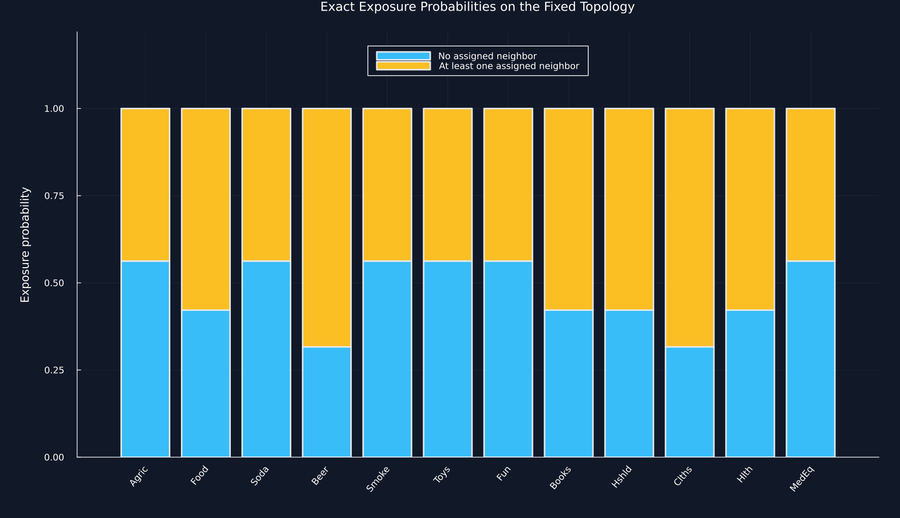

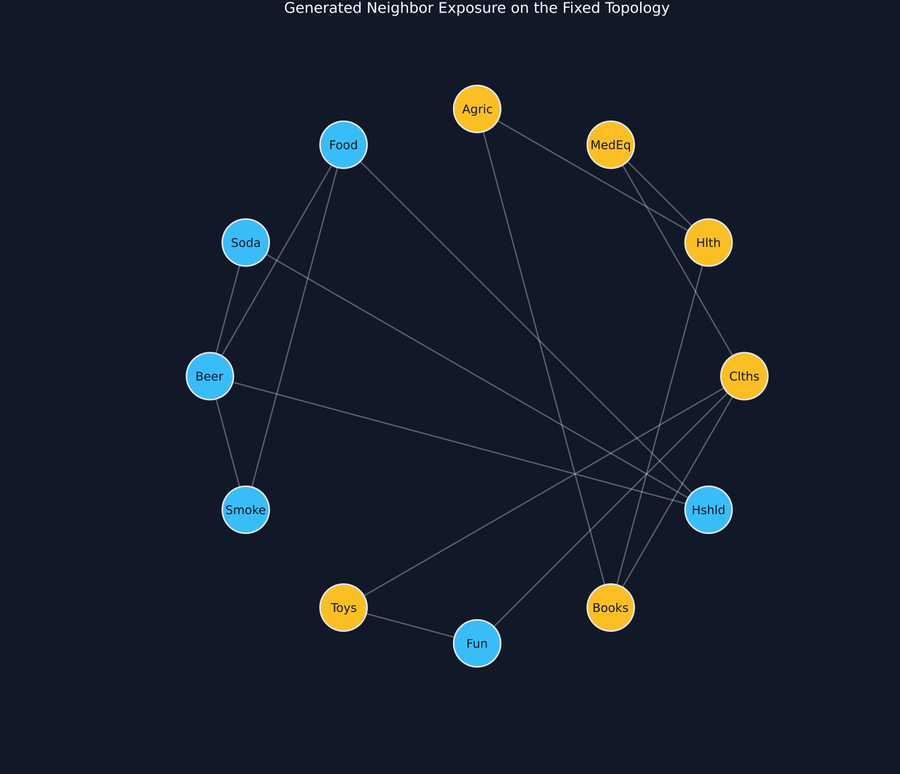

In [2]:
assignment_probability_value=.25
assignment_random_state=7101
assignment=Int.(vec(normal_block(store,"mapping")))
realized_exposure=exposure_labels(adjacency,assignment)
probabilities=exposure_probabilities(adjacency,assignment_probability_value)
mapping_definition = frame(["Symbol","Definition"],[["Z_j","Random assignment of unit j"],["A_ij","Supplied undirected link between units i and j"],["D_i(Z)","One when at least one declared neighbor of i is assigned"],["pi_i(d)","Randomization probability that unit i has exposure d"]])
table(mapping_definition,"mapping_definition")
assignment_table=DataFrame("Industry"=>industries,"Degree"=>degrees,"Own assignment"=>assignment,"Assigned neighbors"=>adjacency*assignment,"Realized exposure"=>realized_exposure)
table(assignment_table,"mapping_public_assignment")
probability_table=DataFrame("Industry"=>industries,"Degree"=>degrees,"Probability of no assigned neighbor"=>probabilities[:,1],"Probability of at least one assigned neighbor"=>probabilities[:,2],"Largest inverse probability"=>1 ./vec(minimum(probabilities;dims=2)))
table(probability_table,"mapping_public_probabilities")
assignment_contract=frame(["Parameter","Value"],[("Assignment probability",assignment_probability_value),("Random state",assignment_random_state),("Assigned industries",sum(assignment)),("Industries with exposed neighbors",sum(realized_exposure)),("Observed financial outcome used","None")])
table(assignment_contract,"mapping_assignment_contract")
probability_plot=probability_table[:,1:4]
save_data(probability_plot,paths,"mapping_public_probabilities")
figure=bar(1:12,probabilities[:,1];color=palette.cyan,label="No assigned neighbor",xticks=(1:12,industries),xrotation=50,ylabel="Exposure probability",title="Exact Exposure Probabilities on the Fixed Topology",ylims=(0,1.22),size=(1180,680),legend=:top)
bar!(figure,1:12,ones(12);fillrange=probabilities[:,1],color=palette.amber,label="At least one assigned neighbor")
save_figure(figure,paths,"mapping_public_probabilities")
assignment_plot=copy(assignment_table)
assignment_plot[!,"X"]=positions[:,1]
assignment_plot[!,"Y"]=positions[:,2]
save_data(assignment_plot,paths,"mapping_public_assignment_nodes")
figure=network_figure(adjacency,industries,realized_exposure,"Generated Neighbor Exposure on the Fixed Topology")
save_figure(figure,paths,"mapping_public_assignment")


## Exact Marginal Exposure Probabilities

Suppose assignments are independent with $\Pr(Z_j=1)=p$. If unit $i$ has degree $d_i$, then

$$
\pi_i(0)=(1-p)^{d_i},\qquad \pi_i(1)=1-(1-p)^{d_i}.
$$

Here, $\pi_i(0)$ is the probability that none of unit $i$'s neighbors is assigned, while $\pi_i(1)$ is the probability that at least one is assigned. Both probabilities must be positive for a contrast between the two exposure conditions.

In [3]:
ring=ring_graph(4)
ring_probability=.35
ring_assignments=all_assignments(4)
ring_rows=[]
for unit in 1:4
    exact_positive=sum(assignment_probability(vector,ring_probability)*exposure_labels(ring,vector)[unit] for vector in ring_assignments)
    formula_positive=exposure_probabilities(ring,ring_probability)[unit,2]
    push!(ring_rows,(unit-1,sum(ring[unit,:]),exact_positive,formula_positive,abs(exact_positive-formula_positive)))
end
ring_probability_check=frame(["Unit","Degree","Enumerated probability","Formula probability","Absolute difference"],ring_rows)
@assert all(isapprox.(ring_probability_check[:,3],ring_probability_check[:,4]))
table(ring_probability_check,"mapping_probability_check")
section_summary = frame(["Result","Value"],[["Public topology","12 industries and 16 descriptive edges"],["Exposure rule","At least one assigned neighbor"],["Assignment source","Generated independent Bernoulli draws"],["Probability check","Enumeration equals the closed form"],["Causal network claim","None from the public correlations"]])
table(section_summary,"mapping_section_summary")


Row,Unit,Degree,Enumerated probability,Formula probability,Absolute difference
,Int64,Int64,Float64,Float64,Float64
1,0,2,0.5775,0.5775,1.11022e-16
2,1,2,0.5775,0.5775,1.11022e-16
3,2,2,0.5775,0.5775,1.11022e-16
4,3,2,0.5775,0.5775,1.11022e-16


Row,Result,Value
,String,String
1,Public topology,12 industries and 16 descriptive edges
2,Exposure rule,At least one assigned neighbor
3,Assignment source,Generated independent Bernoulli draws
4,Probability check,Enumeration equals the closed form
5,Causal network claim,None from the public correlations
